In [1]:
# Import the libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [2]:
# Folder for my charts
os.makedirs("images", exist_ok=True)
files.upload()

Saving Automobile.csv to Automobile.csv


{'Automobile.csv': b"name,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin\r\nchevrolet chevelle malibu,18,8,307,130,3504,12,70,usa\r\nbuick skylark 320,15,8,350,165,3693,11.5,70,usa\r\nplymouth satellite,18,8,318,150,3436,11,70,usa\r\namc rebel sst,16,8,304,150,3433,12,70,usa\r\nford torino,17,8,302,140,3449,10.5,70,usa\r\nford galaxie 500,15,8,429,198,4341,10,70,usa\r\nchevrolet impala,14,8,454,220,4354,9,70,usa\r\nplymouth fury iii,14,8,440,215,4312,8.5,70,usa\r\npontiac catalina,14,8,455,225,4425,10,70,usa\r\namc ambassador dpl,15,8,390,190,3850,8.5,70,usa\r\ndodge challenger se,15,8,383,170,3563,10,70,usa\r\nplymouth 'cuda 340,14,8,340,160,3609,8,70,usa\r\nchevrolet monte carlo,15,8,400,150,3761,9.5,70,usa\r\nbuick estate wagon (sw),14,8,455,225,3086,10,70,usa\r\ntoyota corona mark ii,24,4,113,95,2372,15,70,japan\r\nplymouth duster,22,6,198,95,2833,15.5,70,usa\r\namc hornet,18,6,199,97,2774,15.5,70,usa\r\nford maverick,21,6,200,85,2587,16,70,usa\r\ndatsu

In [3]:
# Read the file
df = pd.read_csv("Automobile.csv")
df.head()

,name,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
0,chevrolet chevelle malibu,18.0,8,307.0,130.0,3504,12.0,70,usa
1,buick skylark 320,15.0,8,350.0,165.0,3693,11.5,70,usa
2,plymouth satellite,18.0,8,318.0,150.0,3436,11.0,70,usa
3,amc rebel sst,16.0,8,304.0,150.0,3433,12.0,70,usa
4,ford torino,17.0,8,302.0,140.0,3449,10.5,70,usa


In [4]:
# Checking the info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   name          398 non-null    object 
 1   mpg           398 non-null    float64
 2   cylinders     398 non-null    int64  
 3   displacement  398 non-null    float64
 4   horsepower    392 non-null    float64
 5   weight        398 non-null    int64  
 6   acceleration  398 non-null    float64
 7   model_year    398 non-null    int64  
 8   origin        398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


In [5]:
df.describe(include="all")

,name,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
count,398,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398
unique,305,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3
top,ford pinto,NaN,NaN,NaN,NaN,NaN,NaN,NaN,usa
freq,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,249
mean,NaN,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050,NaN
std,NaN,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627,NaN
min,NaN,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,NaN
25%,NaN,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000,NaN
50%,NaN,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000,NaN
75%,NaN,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000,NaN


In [6]:
# Checking the duplicates
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [7]:
# Checking null values
df.isnull().sum()

,0
name,0
mpg,0
cylinders,0
displacement,0
horsepower,6
weight,0
acceleration,0
model_year,0
origin,0


In [8]:
# Brand is the first word of the car name
df["brand"] = df["name"].str.split().str[0]

In [9]:
# fixing spelling mistakes in the brand names
# capri is a Mercury model and hi is International Harvester
fix = {"chevroelt": "chevrolet", "chevy": "chevrolet", "vw": "volkswagen",
       "vokswagen": "volkswagen", "toyouta": "toyota", "maxda": "mazda",
       "mercedes-benz": "mercedes", "capri": "mercury", "hi": "international"}
df["brand"] = df["brand"].replace(fix)

In [10]:
# Fill the 6 missing horsepower values with the median of cars from the same brand
df["horsepower"] = df["horsepower"].fillna(
    df.groupby("brand")["horsepower"].transform("median")
)

# if a brand had no horsepower at all, use the overall median
df["horsepower"] = df["horsepower"].fillna(df["horsepower"].median())

print("Missing horsepower left:", df["horsepower"].isna().sum())

Missing horsepower left: 0


In [11]:
# Add column Four-digit year
df["year"] = 1900 + df["model_year"]

# Add column Litres per 100 km (lower is better)
df["weight_kg"] = (df["weight"] * 0.4536).round(2)

# Add column Weight in kg
df["l_per_100km"] = (235.215 / df["mpg"]).round(2)

#Add diesel column
extra_diesels = ["mercedes benz 300d", "mercedes-benz 240d"]
df["is_diesel"] = (df["name"].str.contains("diesel")
                   | df["name"].isin(extra_diesels)).astype(int)

# Add column Unique id
df.insert(0, "car_id", range(1, len(df) + 1))

In [12]:
# Adding an new column Three eras based on real events
def get_era(year):
  if year <= 1973:
    return "Cheap fuel"
  elif year <= 1978:
    return "Oil crisis shock"
  else:
    return "Downsizing"

df["era"] = df["year"].apply(get_era)

In [13]:
#  Average mpg, horsepower and weight for each era and origin
summary = df.groupby(["era", "origin"]).agg(
    cars = ("car_id", "count"),
    avg_mpg = ("mpg", "mean"),
    avg_hp = ("horsepower", "mean"),
    avg_weight_kg = ("weight_kg", "mean")
).round(1)
summary

cars  avg_mpg  avg_hp  avg_weight_kg
era              origin                                      
Cheap fuel       europe    21     24.7    80.9         1055.3
                 japan     15     24.7    90.9         1008.1
                 usa       89     16.0   143.7         1666.1
Downsizing       europe    19     34.9    69.3         1120.1
                 japan     36     34.3    76.7         1010.4
                 usa       63     26.5    95.1         1305.9
Oil crisis shock europe    30     25.7    86.7         1116.7
                 japan     28     28.6    78.0         1003.5
                 usa       97     19.6   110.9         1537.7

In [14]:
# For each year, fit mpg aganist weight to get the expected mpg
parts = []
for year, group in df.groupby("year"):
  group = group.copy()
  slope, intercept = np.polyfit(group["weight"], group["mpg"], 1)
  group["expected_mpg"] = (slope * group["weight"] + intercept).round(2)
  parts.append(group)

df = pd.concat(parts).sort_index()

# Gap = actual mpg minus expected mpg
df["efficiency_gap"] = (df["mpg"] - df["expected_mpg"]).round(2)

# Top 10 cars that beat their peers
df.sort_values("efficiency_gap", ascending=False)[
    ["name", "year", "origin", "weight", "mpg", "expected_mpg", "efficiency_gap"]
].head(10)

,name,year,origin,weight,mpg,expected_mpg,efficiency_gap
387,oldsmobile cutlass ciera (diesel),1982,usa,3015,38.0,25.59,12.41
244,volkswagen rabbit custom diesel,1978,europe,1985,43.1,32.52,10.58
322,mazda glc,1980,japan,2110,46.6,37.34,9.26
394,vw pickup,1982,europe,2130,44.0,35.24,8.76
326,vw dasher (diesel),1980,europe,2335,43.4,34.83,8.57
327,audi 5000s (diesel),1980,europe,2950,36.4,27.97,8.43
247,datsun b210 gx,1978,japan,2070,39.4,31.70,7.70
325,vw rabbit c (diesel),1980,europe,2085,44.3,37.62,6.68
364,oldsmobile cutlass ls,1981,usa,3725,26.6,19.96,6.64
360,volvo diesel,1981,europe,3160,30.7,24.83,5.87


In [15]:
# A car is on the frontier if no car of the same year is better in both mpg and horsepower
df["on_frontier"] = 0

for i, row in df.iterrows():
  same_year = df[df["year"] == row["year"]]
  better = same_year[
        (same_year["mpg"] >= row["mpg"])
        & (same_year["horsepower"] >= row["horsepower"])
        & ((same_year["mpg"] > row["mpg"]) | (same_year["horsepower"] > row["horsepower"]))
    ]
  if len(better) == 0:
      df.loc[i, "on_frontier"] = 1

print("Frontier cars:", df["on_frontier"].sum())

# Share of frontier cars by origin
(df.groupby("origin")["on_frontier"].mean() * 100).round(1)

Frontier cars: 102


,on_frontier
origin,
europe,30.0
japan,41.8
usa,19.3


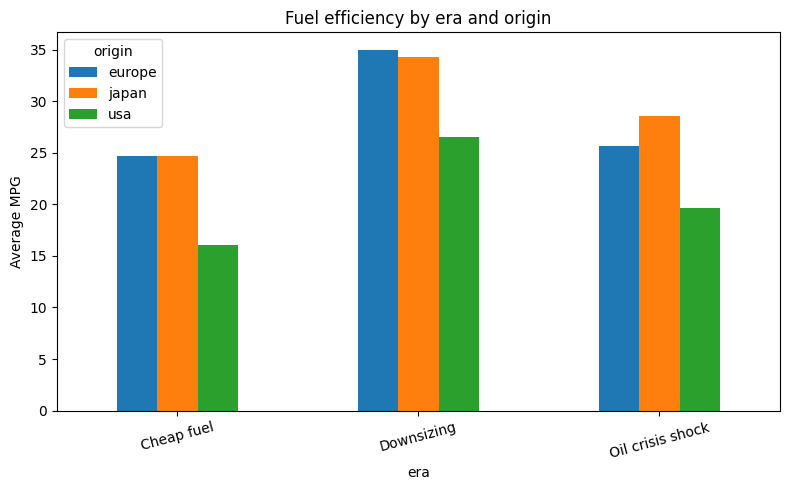

In [16]:
# Chart 1: mpg by era and origin
df.groupby(["era", "origin"])["mpg"].mean().unstack().plot(kind="bar", figsize=(8, 5))
plt.ylabel("Average MPG")
plt.title("Fuel efficiency by era and origin")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("images/mpg_by_era.png", dpi=150)
plt.show()

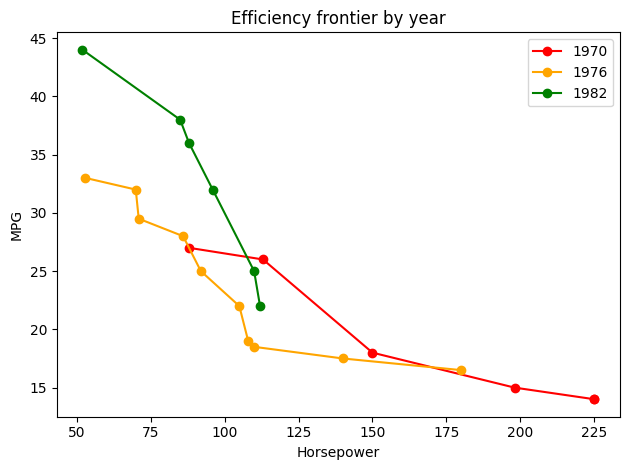

In [17]:
# Chart 2: frontier in three years
for year, color in [(1970, "red"), (1976, "orange"), (1982, "green")]:
    data = df[(df["year"] == year) & (df["on_frontier"] == 1)].sort_values("horsepower")
    plt.plot(data["horsepower"], data["mpg"], marker="o", color=color, label=year)
plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.title("Efficiency frontier by year")
plt.legend()
plt.tight_layout()
plt.savefig("images/frontier_by_year.png", dpi=150)
plt.show()

In [18]:
# Fixed column order so the SQL import works
df = df[[
    "car_id", "name", "mpg", "cylinders", "displacement", "horsepower",
    "weight", "acceleration", "model_year", "origin", "brand", "year",
    "era", "l_per_100km", "weight_kg", "is_diesel", "expected_mpg",
    "efficiency_gap", "on_frontier",
]]

# checks before saving, so a broken file never reaches SQL
print("Rows:", len(df))                                      # expect 398
print("Duplicate car_id:", df["car_id"].duplicated().sum())  # expect 0
print("Missing values:", df.isna().sum().sum())              # expect 0
print("Frontier cars:", df["on_frontier"].sum())             # expect 102
print("Eras:", df["era"].unique())                           # expect 3 labels
print("Column 13:", df.columns[13])

df.to_csv("automobile_clean.csv", index=False)
files.download("automobile_clean.csv")

Rows: 398
Duplicate car_id: 0
Missing values: 0
Frontier cars: 102
Eras: ['Cheap fuel' 'Oil crisis shock' 'Downsizing']
Column 13: l_per_100km


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>